# 🔍 Lab: Explaining a Sentiment Model with **LIME**, **SHAP** & **Integrated Gradients**

**Dataset:** IMDB Movie Reviews (50k reviews, positive / negative) &nbsp;|&nbsp; **Model:** DistilBERT fine-tuned for sentiment &nbsp;|&nbsp; **Time:** ~90 min

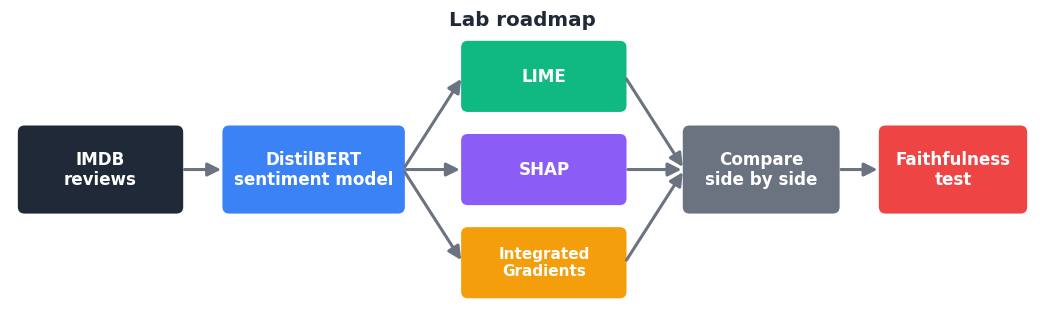

### 🎯 Aim
To explain *why* a text classifier makes a prediction, using three explainability (XAI) methods, and to compare how much we can trust each explanation.

### ✅ By the end you will be able to
1. Generate word-level explanations with LIME, SHAP and Integrated Gradients (IG)
2. Change each method's knobs and **see** how the explanation changes
3. Compare the three methods on the same review
4. Measure which explanation is most **faithful** using a deletion test

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>How this lab works:</b> every section has a 🎮 <b>interactive cell</b> with sliders, dropdowns and buttons. Run it, play with it, and answer the ✍️ checkpoint questions. You can also type <b>your own review</b> into any text box.</div>

**Sections:** 0 Setup → 1 Data → 2 Model → 3 LIME → 4 SHAP → 5 Integrated Gradients → 6 Comparison → 7 Faithfulness test → 8 Wrap-up

## 0️⃣ Setup

<div style="background:#fffbeb;border-left:5px solid #F59E0B;padding:10px 14px;border-radius:6px;color:#111">⚠️ <b>Google Colab users:</b> Runtime → Change runtime type → <b>T4 GPU</b>. It also runs on CPU, just slower (SHAP and IG take a few seconds more per review).</div>

In [1]:
# Install the XAI libraries (takes ~1 minute). torch is preinstalled on Colab.
!pip install -q transformers datasets lime shap captum ipywidgets plotly

In [2]:
import re, time, random, warnings, html as _html
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["NEGATIVE", "POSITIVE"]
print(f"✅ Ready | device = {device} | torch {torch.__version__}")

✅ Ready | device = cuda | torch 2.6.0+cu124


## 1️⃣ Meet the data: IMDB movie reviews

The **IMDB Large Movie Review** dataset (Maas et al., 2011) contains 50,000 movie reviews, each labelled **positive (1)** or **negative (0)**. It is one of the most widely used benchmarks for sentiment analysis.

We load the test split and pick **200 short reviews (25–70 words)** so that explanations are fast and easy to read.

Full test split: 25,000 reviews | demo set: 200 short reviews


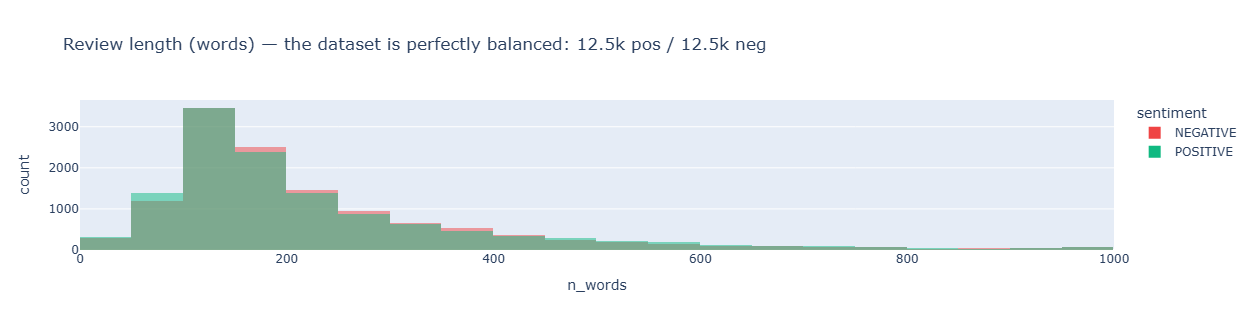

In [3]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb", split="test")
df = ds.to_pandas()
df["text"] = (df["text"].str.replace(r"<br\s*/?>", " ", regex=True)   # remove HTML line breaks
                        .str.replace(r"\s+", " ", regex=True).str.strip())
df["n_words"] = df["text"].str.split().str.len()
df["sentiment"] = df["label"].map(dict(enumerate(LABELS)))

short = df["n_words"].between(25, 70)
demo_df = (pd.concat([df[short & (df.label == c)].sample(100, random_state=SEED) for c in (0, 1)])
             .sample(frac=1, random_state=SEED).reset_index(drop=True))

print(f"Full test split: {len(df):,} reviews | demo set: {len(demo_df)} short reviews")
fig = px.histogram(df, x="n_words", color="sentiment", nbins=100, range_x=[0, 1000], barmode="overlay",
                   color_discrete_map={"POSITIVE": "#10B981", "NEGATIVE": "#EF4444"},
                   title="Review length (words) — the dataset is perfectly balanced: 12.5k pos / 12.5k neg")
fig.update_layout(height=330); fig.show()

### 🎮 Browse the reviews
Drag the slider. Before reading the label, **guess the sentiment yourself** — that's the kind of reasoning we want the model to reveal.

In [4]:
def review_card(i):
    r = demo_df.iloc[i]
    color = "#10B981" if r.label == 1 else "#EF4444"
    display(HTML(f"""<div style='border:1px solid #e5e7eb;border-radius:10px;padding:12px;background:#fff;color:#111'>
      <span style='background:{color};color:white;padding:2px 10px;border-radius:12px;font-size:12px'>{r.sentiment}</span>
      <span style='color:#666;font-size:12px'>&nbsp; {r.n_words} words</span>
      <p style='margin-top:8px;line-height:1.6'>{_html.escape(r.text)}</p></div>"""))

widgets.interact(review_card, i=widgets.IntSlider(0, 0, len(demo_df) - 1, description="Review #",
                                                   continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='Review #', max=199), Output()),…

## 2️⃣ The black box: DistilBERT sentiment classifier

We use **`distilbert-base-uncased-finetuned-sst-2-english`** — a small Transformer (66M parameters) fine-tuned on movie-review sentences (SST-2). We **do not train** anything; our job is to *explain* this model.

All three explainers only need one thing from us: a function **`predict_proba(list_of_texts) → [[P(neg), P(pos)], ...]`**.

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval()
print("Label mapping:", model.config.id2label)   # {0: 'NEGATIVE', 1: 'POSITIVE'}

@torch.no_grad()
def predict_proba(texts, batch_size=32):
    """list of strings -> numpy array (n, 2) of class probabilities"""
    if isinstance(texts, str):
        texts = [texts]
    texts = [str(t) for t in texts]
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=256, return_tensors="pt").to(device)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(out)
probs = predict_proba(["A wonderful, moving film.","bad"]).round(3)

print("Negative probability:", probs[0][0])
print("Positive probability:", probs[0][1])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Label mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}
Negative probability: 0.0
Positive probability: 1.0


In [10]:
print("Negative probability:", probs[1][0])
print("Positive probability:", probs[1][1])

Negative probability: 1.0
Positive probability: 0.0


### 📊 How good is the black box on our 200 reviews?

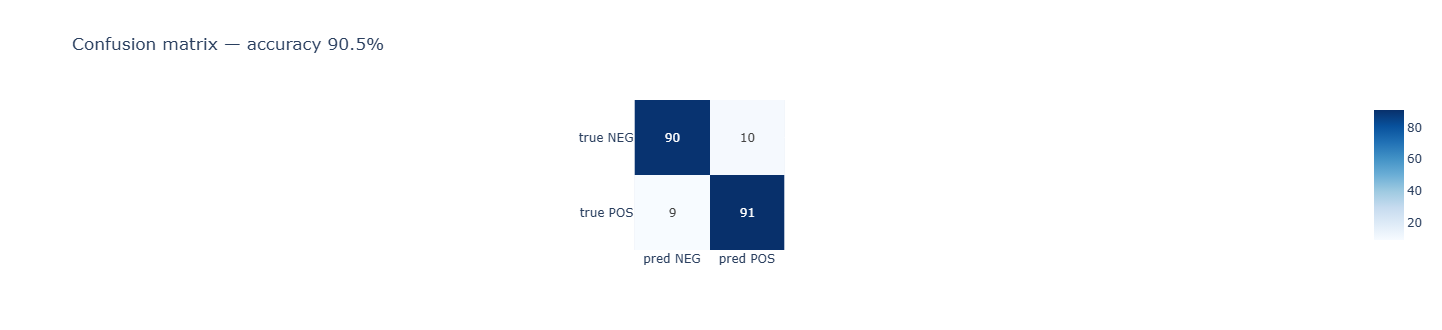

❌ 19 mistakes. Most confident ones (great candidates to explain later!):


,text,sentiment,confidence
42,I was pleasantly surprised with this one. It's...,NEGATIVE,0.999789
186,"The screen-play is very bad, but there are som...",NEGATIVE,0.999462
19,"Well, I don't normally think there's such a th...",NEGATIVE,0.999448


In [11]:
from sklearn.metrics import confusion_matrix

probs = predict_proba(demo_df.text.tolist())
demo_df["p_pos"] = probs[:, 1]
demo_df["pred"] = (probs[:, 1] >= 0.5).astype(int)
acc = (demo_df.pred == demo_df.label).mean()

cm = confusion_matrix(demo_df.label, demo_df.pred, labels=[0, 1])
fig = px.imshow(cm, text_auto=True, x=["pred NEG", "pred POS"], y=["true NEG", "true POS"],
                color_continuous_scale="Blues", title=f"Confusion matrix — accuracy {acc:.1%}")
fig.update_layout(height=330, width=420); fig.show()

wrong = demo_df[demo_df.pred != demo_df.label].copy()
wrong["confidence"] = np.where(wrong.pred == 1, wrong.p_pos, 1 - wrong.p_pos)
print(f"❌ {len(wrong)} mistakes. Most confident ones (great candidates to explain later!):")
display(wrong.sort_values("confidence", ascending=False)[["text", "sentiment", "confidence"]].head(3))

### 🎮 Prediction playground
Type anything, or click an example. Notice the tricky ones — **negation**, **sarcasm**, **mixed opinions**.

In [12]:
def prob_html(p_pos):
    lab = "POSITIVE 😀" if p_pos >= 0.5 else "NEGATIVE 😞"
    return (f"<div style='font-size:14px;margin:6px 0'><b>Prediction:</b> {lab} &nbsp; P(positive) = <b>{p_pos:.3f}</b>"
            f"<div style='background:#fecaca;border-radius:6px;height:14px;width:320px;margin-top:4px'>"
            f"<div style='background:#10B981;height:14px;border-radius:6px;width:{p_pos*100:.1f}%'></div></div></div>")

examples = ["The movie was not bad at all.",
            "Oh great, another two hours of my life I will never get back.",
            "Brilliant acting, but the plot was painfully boring.",
            "I expected to hate it, yet I loved every minute."]
box = widgets.Textarea(value=examples[0], layout=widgets.Layout(width="95%", height="60px"))
out = widgets.Output()

def run(_=None):
    with out:
        clear_output(wait=True)
        display(HTML(prob_html(predict_proba(box.value)[0, 1])))

buttons = []
for ex in examples:
    b = widgets.Button(description=ex[:28] + "…", layout=widgets.Layout(width="auto"), tooltip=ex)
    b.on_click(lambda _, ex=ex: (setattr(box, "value", ex), run()))
    buttons.append(b)
go_btn = widgets.Button(description="Predict ▶", button_style="primary")
go_btn.on_click(run)
display(widgets.HBox(buttons), box, go_btn, out); run()

Textarea(value='The movie was not bad at all.', layout=Layout(height='60px', width='95%'))

Button(button_style='primary', description='Predict ▶', style=ButtonStyle())

Output()

### 🧰 Shared helpers (run once)
Every method below returns **one score per word** of the review, measured as *contribution to P(positive)*. That way all three can be drawn and compared the same way:
🟩 green = pushes toward POSITIVE, 🟥 red = pushes toward NEGATIVE.

In [13]:
def highlight(words, scores, title="", note=""):
    """Colour each word by its score (hover to see the number)."""
    scores = np.asarray(scores, dtype=float)
    m = np.abs(scores).max() if len(scores) and np.abs(scores).max() > 0 else 1.0
    spans = []
    for w, s in zip(words, scores):
        a = min(1.0, abs(s) / m) * 0.85
        rgb = "16,185,129" if s > 0 else "239,68,68"
        spans.append(f"<span title='score = {s:+.4f}' style='background:rgba({rgb},{a:.2f});color:#111;"
                     f"padding:2px 4px;margin:2px 1px;border-radius:5px;display:inline-block'>{_html.escape(w)}</span>")
    head = (f"<div style='font-weight:600;margin-bottom:6px'>{title} "
            f"<span style='font-weight:400;color:#666;font-size:12px'>{note}</span></div>") if title else ""
    return (f"<div style='border:1px solid #e5e7eb;border-radius:10px;padding:10px 12px;margin:6px 0;"
            f"background:#fff;color:#111;line-height:1.9;font-size:14px'>{head}{' '.join(spans)}</div>")

LEGEND = HTML("<div style='font-size:12px;color:#555'>🟩 pushes toward <b>POSITIVE</b> &nbsp; "
              "🟥 pushes toward <b>NEGATIVE</b> &nbsp; (hover a word for its exact score)</div>")

def top_bar(words, scores, title, k=10):
    scores = np.asarray(scores, dtype=float)
    idx = np.argsort(-np.abs(scores))[:k][::-1]
    fig = go.Figure(go.Bar(x=scores[idx], y=[f"{words[i]} ·{i}" for i in idx], orientation="h",
                           marker_color=["#10B981" if scores[i] > 0 else "#EF4444" for i in idx]))
    fig.update_layout(title=title, height=110 + 26 * len(idx), margin=dict(l=10, r=10, t=50, b=30),
                      xaxis_title="contribution to P(positive)")
    return fig

def align_to_words(text, tokens, scores):
    """Map sub-word token scores (SHAP / IG) back onto whitespace words of the text by summing."""
    spans = [(m.start(), m.end(), m.group()) for m in re.finditer(r"\S+", text)]
    low, cursor = text.lower(), 0
    word_scores = np.zeros(len(spans))
    for tok, s in zip(tokens, scores):
        t = str(tok).replace("##", "").strip().lower()
        if not t or t in {"[cls]", "[sep]", "[pad]", "[unk]", "[mask]"}:
            continue
        pos = low.find(t, cursor)
        if pos == -1:
            continue
        cursor = pos + len(t)
        for i, (a, b, _) in enumerate(spans):
            if a <= pos < b:
                word_scores[i] += s
                break
    return [w for _, _, w in spans], word_scores

def review_picker(default=0, n=60):
    """Dropdown of demo reviews + editable text box (type your own review!)."""
    opts = [(f"#{i} [{'POS' if l == 1 else 'NEG'}] {t[:70]}…", i)
            for i, (t, l) in enumerate(zip(demo_df.text[:n], demo_df.label[:n]))]
    dd = widgets.Dropdown(options=opts, value=default, description="Review:", layout=widgets.Layout(width="95%"))
    ta = widgets.Textarea(value=demo_df.text[default], layout=widgets.Layout(width="95%", height="90px"))
    dd.observe(lambda ch: setattr(ta, "value", demo_df.text[ch["new"]]), names="value")
    return dd, ta

CACHE = {}
def cached(method, text, **kw):
    """Run explain_<method>(text, **kw) once and remember the result (plus run time)."""
    key = (method, text, tuple(sorted(kw.items())))
    if key not in CACHE:
        t0 = time.time()
        res = globals()[f"explain_{method.lower()}"](text, **kw)
        res["time"] = time.time() - t0
        CACHE[key] = res
    return CACHE[key]

def quiz(question, options, correct, why):
    rb = widgets.RadioButtons(options=options, value=None, layout=widgets.Layout(width="auto"))
    btn, out = widgets.Button(description="Check answer", button_style="info"), widgets.Output()
    def check(_):
        with out:
            clear_output()
            if rb.value is None:
                print("👉 Pick an option first."); return
            ok = rb.value == options[correct]
            display(HTML(f"<b style='color:{'#10B981' if ok else '#EF4444'}'>{'✅ Correct!' if ok else '❌ Not quite.'}</b> {why}"))
    btn.on_click(check)
    display(widgets.VBox([widgets.HTML(f"<b>✍️ {question}</b>"), rb, btn, out]))

sample_text = demo_df.text[0]
print("✅ Helpers loaded. Sample review:\n", sample_text)

✅ Helpers loaded. Sample review:
 This started out slow, then got worse. The best parts of this were all seen in the previews. Bad Apple has the feel of a pilot - if that's the case TNT should save their money.


## 3️⃣ LIME — *Local Interpretable Model-agnostic Explanations*

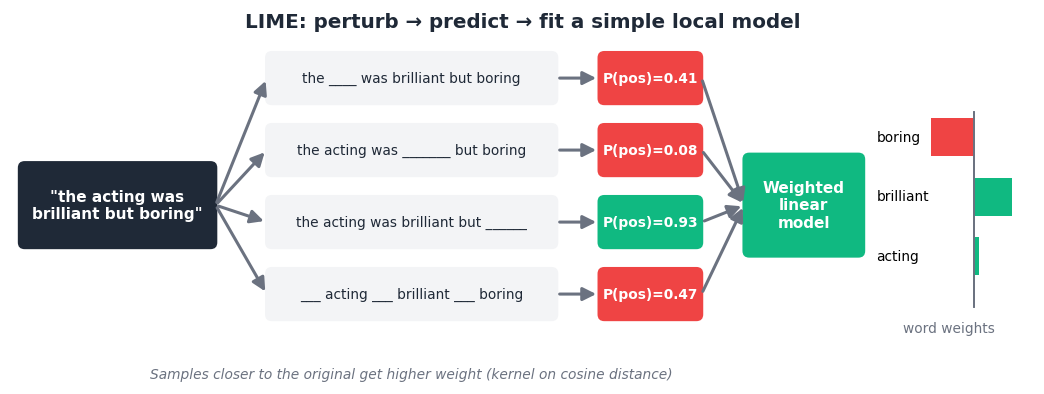

**Idea in 4 steps** (Ribeiro et al., 2016):
1. **Perturb** — make many copies of the review with random words removed
2. **Predict** — ask the black box for P(positive) on every copy
3. **Weight** — copies that look more like the original count more
4. **Fit** — train a small *linear* model on "which words were present" → its coefficients are the explanation

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 LIME is <b>model-agnostic</b>: it only calls <code>predict_proba</code>. It would work the same for an SVM, an LSTM or GPT.</div>

**Knobs you will play with:** `num_samples` (how many perturbed copies) and `num_features` (how many words to show).

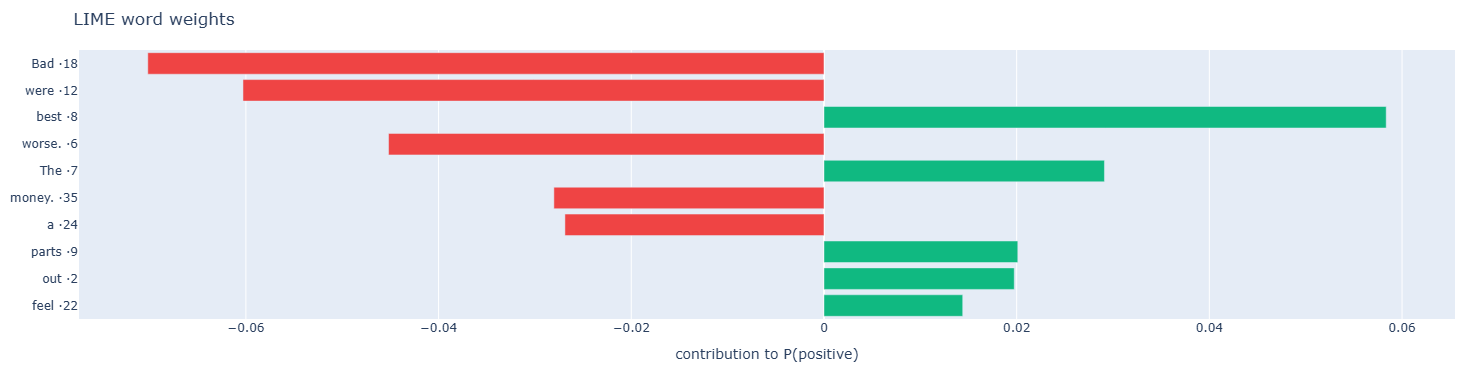

Local surrogate R² = 0.19  (how well the linear model mimics the black box near this review)


In [14]:
from lime.lime_text import LimeTextExplainer

def explain_lime(text, num_features=10, num_samples=1000, seed=SEED):
    explainer = LimeTextExplainer(class_names=LABELS, random_state=seed)
    exp = explainer.explain_instance(text, predict_proba, num_features=num_features,
                                     num_samples=num_samples, labels=(1,))
    weights = dict(exp.as_list(label=1))                       # {word: weight toward POSITIVE}
    words = text.split()
    scores = np.array([sum(weights.get(p, 0.0) for p in re.split(r"\W+", w) if p) for w in words])
    r2 = exp.score[1] if isinstance(exp.score, dict) else exp.score   # fit quality of the local linear model
    return dict(exp=exp, words=words, scores=scores, weights=weights, r2=float(r2))

t0 = time.time()
lime_res = explain_lime(sample_text)
display(HTML(prob_html(predict_proba(sample_text)[0, 1])))
display(HTML(highlight(lime_res["words"], lime_res["scores"], "LIME", f"top 10 words | {time.time()-t0:.1f}s")), LEGEND)
top_bar(lime_res["words"], lime_res["scores"], "LIME word weights").show()
print(f"Local surrogate R² = {lime_res['r2']:.2f}  (how well the linear model mimics the black box near this review)")

LIME also ships its own visualisation 👇 (probabilities + bar chart + highlighted text):

### 🎮 LIME lab
<div style="background:#eff6ff;border-left:5px solid #3B82F6;padding:10px 14px;border-radius:6px;color:#111">🎯 <b>Try this:</b> (1) Set <code>num_samples</code> = 100 and click Explain a few times with different seeds. (2) Then set 3000. What happens to the explanation and to R²?</div>

In [15]:
dd, ta = review_picker()
nf = widgets.IntSlider(10, 3, 25, description="num_features")
ns = widgets.IntSlider(1000, 100, 3000, step=100, description="num_samples")
sd = widgets.IntText(SEED, description="seed")
btn, out = widgets.Button(description="Explain with LIME ▶", button_style="success"), widgets.Output()

def on_lime(_):
    with out:
        clear_output(wait=True); print("⏳ perturbing & fitting…")
        t0 = time.time()
        r = explain_lime(ta.value, nf.value, ns.value, sd.value)
        clear_output(wait=True)
        display(HTML(prob_html(predict_proba(ta.value)[0, 1])))
        display(HTML(highlight(r["words"], r["scores"], "LIME", f"{ns.value} samples | R² = {r['r2']:.2f} | {time.time()-t0:.1f}s")), LEGEND)
        top_bar(r["words"], r["scores"], "LIME word weights", nf.value).show()

btn.on_click(on_lime)
display(dd, ta, widgets.HBox([nf, ns, sd]), btn, out)

Dropdown(description='Review:', layout=Layout(width='95%'), options=(('#0 [NEG] This started out slow, then go…

Textarea(value="This started out slow, then got worse. The best parts of this were all seen in the previews. B…

Button(button_style='success', description='Explain with LIME ▶', style=ButtonStyle())

Output()

### 🧪 Experiment: is LIME stable?
LIME uses random sampling, so two runs can disagree. Below we run it with **5 different seeds** and draw a heat-map of the word weights. Rows that look alike = stable explanation.

In [16]:
ns2 = widgets.SelectionSlider(options=[100, 250, 500, 1000, 2000], value=250, description="num_samples")
btn2, out2 = widgets.Button(description="Run 5 seeds ▶", button_style="warning"), widgets.Output()

def on_stab(_):
    with out2:
        clear_output(wait=True); print("⏳ running LIME 5×…")
        runs = {f"seed {s}": explain_lime(sample_text, 8, ns2.value, s)["weights"] for s in range(5)}
        tab = pd.DataFrame(runs).T.fillna(0)
        tab = tab[tab.abs().mean().sort_values(ascending=False).index[:12]]
        clear_output(wait=True)
        fig = px.imshow(tab, color_continuous_scale="RdYlGn", color_continuous_midpoint=0, text_auto=".2f",
                        title=f"LIME weights across seeds (num_samples = {ns2.value})")
        fig.update_layout(height=330); fig.show()
        top1 = [str(max(w, key=lambda k: abs(w[k]))) for w in runs.values()]
        print("Most important word per run:", top1, "→", "STABLE ✅" if len(set(top1)) == 1 else "UNSTABLE ⚠️")

btn2.on_click(on_stab)
display(widgets.HBox([ns2, btn2]), out2)

Output()

In [17]:
quiz("Why can LIME give a different explanation every time you run it?",
     ["The DistilBERT model is random", "It explains with randomly sampled perturbations",
      "The tokenizer changes between runs", "Because GPUs are non-deterministic"],
     1, "LIME's explanation depends on which random 'word-removed' copies it samples. More samples → more stable.")

## 4️⃣ SHAP — *SHapley Additive exPlanations*

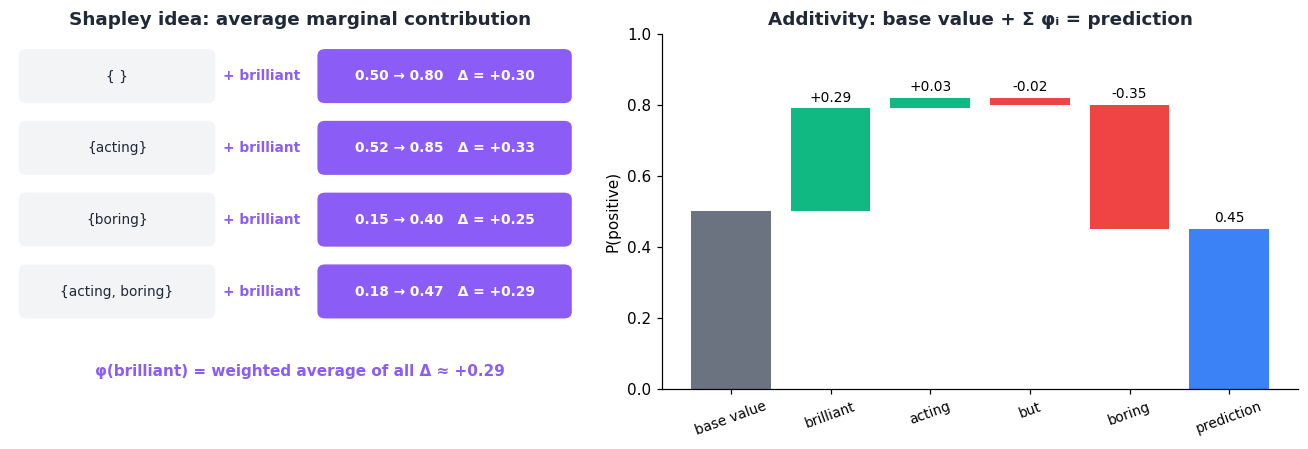

**Idea** (Lundberg & Lee, 2017): treat each word as a **player in a team game** whose payout is the model's prediction. A word's **Shapley value** is its *average extra contribution* when added to every possible group (coalition) of other words.

Key property — **additivity**:
$$ f(x) = \underbrace{\phi_0}_{\text{base value}} + \sum_i \phi_i $$
The base value is the prediction when *all* words are masked; the SHAP values exactly explain the gap to the real prediction.

<div style="background:#f5f3ff;border-left:5px solid #8B5CF6;padding:10px 14px;border-radius:6px;color:#111">🤔 Exact Shapley values need 2ⁿ coalitions (n = number of words) — impossible for long text. SHAP's <b>Partition explainer</b> groups tokens hierarchically and needs only <code>max_evals</code> model calls.</div>

In [18]:
import shap

shap_explainer = shap.Explainer(predict_proba, shap.maskers.Text(tokenizer), output_names=LABELS)

def explain_shap(text, max_evals=500):
    sv = shap_explainer([text], max_evals=max_evals, silent=True)
    tokens = list(sv.data[0])
    tok_scores = np.array(sv.values[0])[:, 1]               # contribution to P(POSITIVE)
    words, scores = align_to_words(text, tokens, tok_scores)
    base = float(np.array(sv.base_values[0])[1])
    return dict(sv=sv, tokens=tokens, tok_scores=tok_scores, words=words, scores=scores, base=base)

t0 = time.time()
shap_res = explain_shap(sample_text)
print(f"⏱ {time.time()-t0:.1f}s")
shap.plots.text(shap_res["sv"][0, :, 1])     # SHAP's interactive text plot (click / hover the tokens)

⏱ 18.6s


### ✔️ Check the additivity property yourself

In [17]:
p = predict_proba(sample_text)[0, 1]
table = pd.DataFrame({"quantity": ["base value φ₀ (all words masked)", "Σ SHAP values", "φ₀ + Σ φᵢ", "model output f(x)"],
                      "value": [shap_res["base"], shap_res["tok_scores"].sum(),
                                shap_res["base"] + shap_res["tok_scores"].sum(), p]})
display(table.style.format({"value": "{:.4f}"}).hide(axis="index"))
display(HTML(highlight(shap_res["words"], shap_res["scores"], "SHAP (word level)")), LEGEND)

quantity,value
base value φ₀ (all words masked),0.5311
Σ SHAP values,-0.5292
φ₀ + Σ φᵢ,0.0019
model output f(x),0.0019


### 🎮 SHAP lab
<div style="background:#eff6ff;border-left:5px solid #3B82F6;padding:10px 14px;border-radius:6px;color:#111">🎯 <b>Try this:</b> lower <code>max_evals</code> to 50 → does the explanation stay sensible? Then pick a review the model got <b>wrong</b> (see section 2) and find the word that fooled it.</div>

In [19]:
dd, ta = review_picker()
me = widgets.IntSlider(500, 50, 1500, step=50, description="max_evals")
btn, out = widgets.Button(description="Explain with SHAP ▶", button_style="success"), widgets.Output()

def on_shap(_):
    with out:
        clear_output(wait=True); print("⏳ computing Shapley values…")
        t0 = time.time()
        r = explain_shap(ta.value, me.value)
        p = predict_proba(ta.value)[0, 1]
        clear_output(wait=True)
        display(HTML(prob_html(p)))
        display(HTML(f"<div style='font-size:13px'>base {r['base']:.3f} + Σφ {r['tok_scores'].sum():+.3f} = "
                     f"<b>{r['base'] + r['tok_scores'].sum():.3f}</b> vs f(x) = <b>{p:.3f}</b> | {time.time()-t0:.1f}s</div>"))
        shap.plots.text(r["sv"][0, :, 1])
        top_bar(r["words"], r["scores"], "SHAP word contributions").show()

btn.on_click(on_shap)
display(dd, ta, me, btn, out)

Dropdown(description='Review:', layout=Layout(width='95%'), options=(('#0 [NEG] This started out slow, then go…

Textarea(value="This started out slow, then got worse. The best parts of this were all seen in the previews. B…

IntSlider(value=500, description='max_evals', max=1500, min=50, step=50)

Button(button_style='success', description='Explain with SHAP ▶', style=ButtonStyle())

Output()

### 🌍 From local to global: which words does the model love / hate?
Averaging SHAP values of the same word over many reviews gives a **global** view of the model.

In [20]:
nrev = widgets.IntSlider(15, 5, 60, step=5, description="# reviews")
btn, out = widgets.Button(description="Aggregate SHAP ▶", button_style="info"), widgets.Output()

def on_global(_):
    with out:
        clear_output(wait=True)
        bar = widgets.IntProgress(0, 0, nrev.value, description="explaining"); display(bar)
        rows = []
        for i in range(nrev.value):
            r = cached("SHAP", demo_df.text[i], max_evals=500)
            rows += [(re.sub(r"\W", "", w.lower()), s) for w, s in zip(r["words"], r["scores"])]
            bar.value = i + 1
        g = pd.DataFrame(rows, columns=["word", "shap"]).query("word != ''")
        g = g.groupby("word")["shap"].agg(["mean", "count"]).query("count >= 2")
        top = pd.concat([g.nlargest(10, "mean"), g.nsmallest(10, "mean")]).sort_values("mean")
        clear_output(wait=True)
        fig = px.bar(top, x="mean", y=top.index, orientation="h", color="mean", color_continuous_scale="RdYlGn",
                     color_continuous_midpoint=0, hover_data=["count"],
                     title=f"Mean SHAP value per word over {nrev.value} reviews (words seen ≥ 2 times)")
        fig.update_layout(height=560, yaxis_title=""); fig.show()

btn.on_click(on_global)
display(widgets.HBox([nrev, btn]), out)

Output()

In [22]:
quiz("For one review, the SHAP base value + the sum of all SHAP values equals…",
     ["0", "1", "the model's predicted probability for that review", "the model's accuracy"],
     2, "That is the additivity (local accuracy) property — SHAP values exactly split up f(x) − base value.")

## 5️⃣ Integrated Gradients (IG)

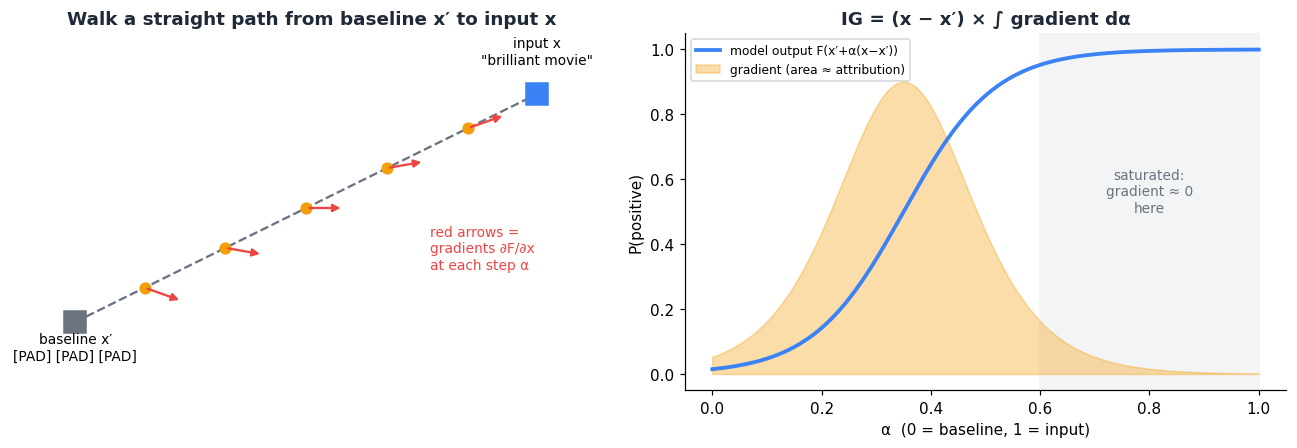

**Problem with plain gradients:** once the model is confident, the output is *saturated* — the gradient at the input is ≈ 0 even for the most important words.

**IG's fix** (Sundararajan et al., 2017): start from a neutral **baseline** x′ (here: all words replaced by `[PAD]`), walk in a straight line to the real input x, and **add up the gradients along the way**:

$$ IG_i(x) = (x_i - x'_i) \times \int_{0}^{1} \frac{\partial F\big(x' + \alpha (x - x')\big)}{\partial x_i} \, d\alpha $$

For text, xᵢ is a word's **embedding vector**; we sum IG over the embedding dimensions to get one score per token.

**Completeness axiom:** Σ IGᵢ = F(x) − F(x′). The gap is reported as the **convergence δ** — smaller is better.

<div style="background:#f5f3ff;border-left:5px solid #8B5CF6;padding:10px 14px;border-radius:6px;color:#111">🤔 IG is <b>white-box</b>: it needs gradients, so the model must be differentiable and we need access to its internals. We use <b>Captum</b>, PyTorch's interpretability library.</div>

In [23]:
from captum.attr import LayerIntegratedGradients

def pos_prob_forward(input_ids, attention_mask):
    return torch.softmax(model(input_ids=input_ids, attention_mask=attention_mask).logits, dim=-1)

emb_layer = model.distilbert.embeddings.word_embeddings
lig = LayerIntegratedGradients(pos_prob_forward, emb_layer)

def encode(text):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(device)
    return enc["input_ids"], enc["attention_mask"]

def make_baseline(ids, kind="PAD"):
    ref = tokenizer.pad_token_id if kind == "PAD" else tokenizer.mask_token_id
    base = torch.full_like(ids, ref)
    base[:, 0], base[:, -1] = ids[:, 0], ids[:, -1]        # keep [CLS] and [SEP]
    return base

def explain_ig(text, n_steps=50, baseline="PAD", target=1):
    ids, mask = encode(text)
    base = make_baseline(ids, baseline)
    attrs, delta = lig.attribute(inputs=ids, baselines=base, additional_forward_args=(mask,), target=target,
                                 n_steps=n_steps, internal_batch_size=25, return_convergence_delta=True)
    tok_scores = attrs.sum(dim=-1)[0].detach().cpu().numpy()   # one score per token
    tokens = tokenizer.convert_ids_to_tokens(ids[0].tolist())
    with torch.no_grad():
        p_x = pos_prob_forward(ids, mask)[0, target].item()
        p_b = pos_prob_forward(base, mask)[0, target].item()
    words, scores = align_to_words(text, tokens, tok_scores)
    return dict(tokens=tokens, tok_scores=tok_scores, words=words, scores=scores,
                delta=abs(float(delta.item())), p_x=p_x, p_b=p_b)

print("✅ Integrated Gradients ready")

✅ Integrated Gradients ready


### 👣 Walk the path yourself
Below we literally feed the model the interpolated embeddings x′ + α(x − x′) for α from 0 → 1 and plot P(positive). IG adds up the slope of this curve, word by word.

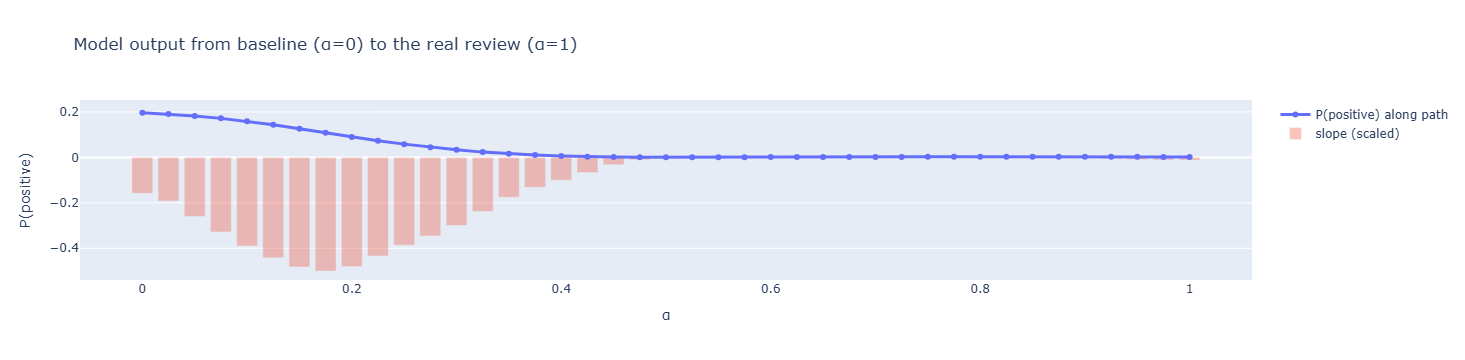

In [24]:
@torch.no_grad()
def path_curve(text, baseline="PAD", steps=41):
    ids, mask = encode(text)
    e_x, e_b = emb_layer(ids), emb_layer(make_baseline(ids, baseline))
    alphas = torch.linspace(0, 1, steps, device=device)
    interp = torch.cat([e_b + a * (e_x - e_b) for a in alphas])
    p = torch.softmax(model(inputs_embeds=interp, attention_mask=mask.expand(steps, -1)).logits, -1)[:, 1]
    return alphas.cpu().numpy(), p.cpu().numpy()

a, p = path_curve(sample_text)
fig = go.Figure()
fig.add_scatter(x=a, y=p, mode="lines+markers", name="P(positive) along path", line=dict(width=3))
fig.add_bar(x=a, y=np.gradient(p, a) / max(1e-9, np.abs(np.gradient(p, a)).max()) * 0.5, name="slope (scaled)",
            opacity=0.35)
fig.update_layout(title="Model output from baseline (α=0) to the real review (α=1)", xaxis_title="α",
                  yaxis_title="P(positive)", height=360)
fig.show()

In [26]:
t0 = time.time()
ig_res = explain_ig(sample_text)
display(HTML(highlight(ig_res["words"], ig_res["scores"], "Integrated Gradients", f"{time.time()-t0:.1f}s")), LEGEND)
display(pd.DataFrame({"quantity": ["F(x)  real review", "F(x′) baseline", "F(x) − F(x′)", "Σ IG attributions", "convergence δ"],
                      "value": [ig_res["p_x"], ig_res["p_b"], ig_res["p_x"] - ig_res["p_b"],
                                ig_res["tok_scores"].sum(), ig_res["delta"]]}).style.format({"value": "{:.4f}"}).hide(axis="index"))

quantity,value
F(x) real review,0.0019
F(x′) baseline,0.1965
F(x) − F(x′),-0.1946
Σ IG attributions,-0.1943
convergence δ,0.0003


### 🎮 IG lab
<div style="background:#eff6ff;border-left:5px solid #3B82F6;padding:10px 14px;border-radius:6px;color:#111">🎯 <b>Try this:</b> (1) Set <code>n_steps</code> = 5 and watch δ. (2) Switch the baseline from <code>PAD</code> to <code>MASK</code> — the explanation changes! IG is only as good as its baseline.</div>

In [27]:
dd, ta = review_picker()
st = widgets.IntSlider(50, 5, 300, step=5, description="n_steps")
bl = widgets.ToggleButtons(options=["PAD", "MASK"], description="baseline")
btn, out = widgets.Button(description="Explain with IG ▶", button_style="success"), widgets.Output()

def on_ig(_):
    with out:
        clear_output(wait=True); print("⏳ integrating gradients…")
        t0 = time.time()
        r = explain_ig(ta.value, st.value, bl.value)
        a, p = path_curve(ta.value, bl.value)
        clear_output(wait=True)
        display(HTML(prob_html(r["p_x"])))
        ok = "✅" if r["delta"] < 0.01 else "⚠️ increase n_steps"
        display(HTML(highlight(r["words"], r["scores"], "Integrated Gradients",
                               f"baseline={bl.value} | n_steps={st.value} | δ = {r['delta']:.4f} {ok} | {time.time()-t0:.1f}s")), LEGEND)
        fig = px.line(x=a, y=p, markers=True, labels={"x": "α", "y": "P(positive)"},
                      title=f"Path from {bl.value} baseline (F={r['p_b']:.2f}) to input (F={r['p_x']:.2f})")
        fig.update_layout(height=300); fig.show()
        top_bar(r["words"], r["scores"], "IG word attributions").show()

btn.on_click(on_ig)
display(dd, ta, widgets.HBox([st, bl]), btn, out)

Dropdown(description='Review:', layout=Layout(width='95%'), options=(('#0 [NEG] This started out slow, then go…

Textarea(value="This started out slow, then got worse. The best parts of this were all seen in the previews. B…

Button(button_style='success', description='Explain with IG ▶', style=ButtonStyle())

Output()

### 🧪 Experiment: how many steps does the integral need?

In [28]:
btn, out = widgets.Button(description="Run convergence test ▶", button_style="warning"), widgets.Output()

def on_conv(_):
    with out:
        clear_output(wait=True)
        steps = [2, 5, 10, 20, 50, 100, 200]
        deltas = []
        for s in steps:
            deltas.append(explain_ig(sample_text, n_steps=s)["delta"]); print(f"n_steps={s:>3}  δ={deltas[-1]:.5f}")
        fig = px.line(x=steps, y=deltas, markers=True, log_x=True, log_y=True,
                      labels={"x": "n_steps (log)", "y": "|convergence δ| (log)"},
                      title="More integration steps → completeness error shrinks")
        fig.update_layout(height=320); fig.show()

btn.on_click(on_conv); display(btn, out)

Button(button_style='warning', description='Run convergence test ▶', style=ButtonStyle())

Output()

In [29]:
quiz("Why does IG integrate gradients along a path instead of using the gradient at the input only?",
     ["It is faster", "At a confident (saturated) input the gradient can be ≈ 0 even for important words",
      "So that no baseline is needed", "To make it model-agnostic"],
     1, "Saturation hides importance. Integrating from the baseline captures the whole change in output (completeness).")

## 6️⃣ Head-to-head: same review, three explanations

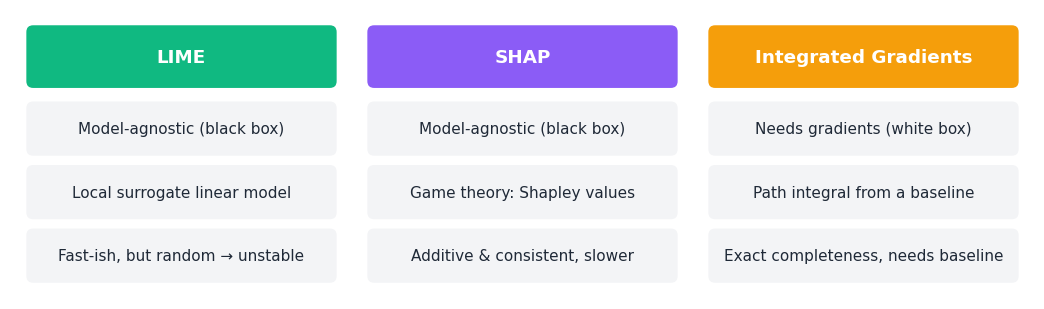

<div style="background:#eff6ff;border-left:5px solid #3B82F6;padding:10px 14px;border-radius:6px;color:#111">🎯 <b>Game:</b> before clicking, type the word <i>you</i> think matters most. We'll see which methods agree with you.</div>

In [30]:
def explain_all(text):
    n = len(text.split())
    return {"LIME": cached("LIME", text, num_features=n, num_samples=1000),
            "SHAP": cached("SHAP", text, max_evals=500),
            "IG":   cached("IG", text, n_steps=50)}

COLORS = {"LIME": "#10B981", "SHAP": "#8B5CF6", "IG": "#F59E0B"}
dd, ta = review_picker(default=1)
guess = widgets.Text(placeholder="your guess, e.g. boring", description="Your guess:")
btn, out = widgets.Button(description="Explain with ALL 3 ▶", button_style="primary"), widgets.Output()

def on_all(_):
    with out:
        clear_output(wait=True); print("⏳ running LIME, SHAP and IG…")
        text = ta.value
        res = explain_all(text)
        words = text.split()
        clear_output(wait=True)
        display(HTML(prob_html(predict_proba(text)[0, 1])), LEGEND)
        for m, r in res.items():
            display(HTML(highlight(r["words"], r["scores"], m, f"{r['time']:.1f}s")))

        # normalised scores (each method scaled to [-1, 1]) for the most important words
        S = pd.DataFrame({m: r["scores"] / max(1e-12, np.abs(r["scores"]).max()) for m, r in res.items()})
        S["word"] = [f"{w} ·{i}" for i, w in enumerate(words)]
        top = S.loc[S[list(res)].abs().max(axis=1).nlargest(12).index]
        fig = go.Figure([go.Bar(name=m, x=top["word"], y=top[m], marker_color=COLORS[m]) for m in res])
        fig.update_layout(barmode="group", title="Normalised word importance (top 12 words)", height=380,
                          yaxis_title="score / max |score|")
        fig.show()

        # agreement: rank correlation + top-5 overlap
        ms = list(res)
        corr = pd.DataFrame([[spearmanr(res[a]["scores"], res[b]["scores"])[0] for b in ms] for a in ms], index=ms, columns=ms)
        top5 = {m: set(np.argsort(-np.abs(res[m]["scores"]))[:5]) for m in ms}
        overlap = pd.DataFrame([[len(top5[a] & top5[b]) / 5 for b in ms] for a in ms], index=ms, columns=ms)
        f1 = px.imshow(corr.round(2), text_auto=True, zmin=-1, zmax=1, color_continuous_scale="RdBu", title="Spearman rank correlation")
        f2 = px.imshow(overlap, text_auto=".0%", zmin=0, zmax=1, color_continuous_scale="Blues", title="Top-5 word overlap")
        for f in (f1, f2): f.update_layout(height=320, width=380); f.show()

        if guess.value.strip():
            g = re.sub(r"\W", "", guess.value.lower())
            for m, r in res.items():
                best = re.sub(r"\W", "", r["words"][int(np.argmax(np.abs(r["scores"])))].lower())
                print(f"{m:>4}: most important word = '{best}'  {'🎉 matches your guess!' if best == g else ''}")

btn.on_click(on_all)
display(dd, ta, guess, btn, out)

Dropdown(description='Review:', index=1, layout=Layout(width='95%'), options=(('#0 [NEG] This started out slow…

Textarea(value='This is a great premise for a movie. The overall plot is very original,interesting, and someth…

Text(value='', description='Your guess:', placeholder='your guess, e.g. boring')

Button(button_style='primary', description='Explain with ALL 3 ▶', style=ButtonStyle())

Output()

<div style="background:#f5f3ff;border-left:5px solid #8B5CF6;padding:10px 14px;border-radius:6px;color:#111">🤔 <b>Discuss:</b> Where do the methods agree? Where do they disagree? Disagreement doesn't mean one is 'wrong' — they answer slightly different questions (local linear fit vs. fair game-theoretic share vs. gradient path from a baseline). So how do we decide which to trust? → next section.</div>

## 7️⃣ Which explanation is most faithful? The deletion test

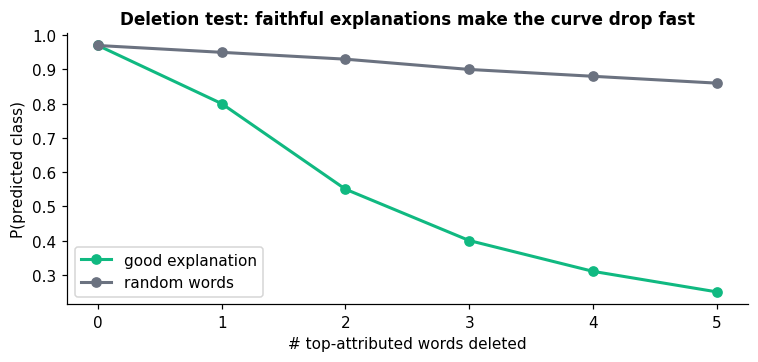

If an explanation is **faithful**, deleting the words it says are most important should make the model's confidence **drop quickly**. We delete the top-k words (k = 1…5) that support the predicted class and compare against deleting **random** words.

**AOPC** (Area Over the Perturbation Curve) = average drop in confidence over k = 1…5. **Higher AOPC = more faithful.**

In [31]:
def deletion_curve(text, order, target, k_max=5):
    words = text.split()
    k_max = min(k_max, len(words) - 1)
    texts = [text] + [" ".join(w for i, w in enumerate(words) if i not in set(order[:k])) for k in range(1, k_max + 1)]
    return predict_proba(texts)[:, target]

def faithfulness(text, res, k_max=5, n_random=5):
    target = int(predict_proba(text)[0, 1] >= 0.5)
    sign = 1 if target == 1 else -1                     # words that SUPPORT the predicted class
    curves = {m: deletion_curve(text, np.argsort(-sign * r["scores"]), target, k_max) for m, r in res.items()}
    rng = np.random.default_rng(SEED)
    n = len(text.split())
    curves["Random"] = np.mean([deletion_curve(text, rng.permutation(n), target, k_max) for _ in range(n_random)], axis=0)
    aopc = {m: float(np.mean(c[0] - c[1:])) for m, c in curves.items()}
    return curves, aopc, target

dd, ta = review_picker(default=2)
btn, out = widgets.Button(description="Run deletion test ▶", button_style="danger"), widgets.Output()

def on_del(_):
    with out:
        clear_output(wait=True); print("⏳ explaining & deleting…")
        res = explain_all(ta.value)
        curves, aopc, target = faithfulness(ta.value, res)
        clear_output(wait=True)
        fig = go.Figure()
        for m, c in curves.items():
            fig.add_scatter(x=list(range(len(c))), y=c, mode="lines+markers", name=f"{m} (AOPC={aopc[m]:.3f})",
                            line=dict(color=COLORS.get(m, "#9CA3AF"), dash="dash" if m == "Random" else "solid", width=3))
        fig.update_layout(title=f"Deleting top-k words — P({LABELS[target]}) should drop fast", xaxis_title="# words deleted",
                          yaxis_title=f"P({LABELS[target]})", height=400)
        fig.show()

btn.on_click(on_del)
display(dd, ta, btn, out)

Dropdown(description='Review:', index=2, layout=Layout(width='95%'), options=(('#0 [NEG] This started out slow…

Textarea(value="Honestly, buying this movie was a waste of money. It's one of the most boring movies I have se…

Button(button_style='danger', description='Run deletion test ▶', style=ButtonStyle())

Output()

### 🏁 Mini-benchmark over many reviews
One review is an anecdote. Let's average AOPC and run time over several reviews (results are cached, so re-runs are fast).

In [29]:
nb_rev = widgets.IntSlider(8, 3, 30, description="# reviews")
btn, out = widgets.Button(description="Run benchmark ▶", button_style="danger"), widgets.Output()
BENCH = None

def on_bench(_):
    global BENCH
    with out:
        clear_output(wait=True)
        bar = widgets.IntProgress(0, 0, nb_rev.value, description="reviews"); display(bar)
        rows = []
        for i in range(nb_rev.value):
            text = demo_df.text[i]
            res = explain_all(text)
            _, aopc, _ = faithfulness(text, res)
            for m in aopc:
                rows.append(dict(review=i, method=m, AOPC=aopc[m], seconds=res[m]["time"] if m in res else 0.0))
            bar.value = i + 1
        BENCH = pd.DataFrame(rows)
        summary = BENCH.groupby("method")[["AOPC", "seconds"]].agg(["mean", "std"]).round(3)
        clear_output(wait=True)
        display(summary)
        fig = px.box(BENCH, x="method", y="AOPC", color="method", points="all",
                     color_discrete_map={**COLORS, "Random": "#9CA3AF"},
                     title=f"Faithfulness (AOPC, higher = better) over {nb_rev.value} reviews")
        fig.update_layout(height=380, showlegend=False); fig.show()
        fig = px.bar(BENCH[BENCH.method != "Random"].groupby("method", as_index=False)["seconds"].mean(),
                     x="method", y="seconds", color="method", color_discrete_map=COLORS, title="Average time per explanation")
        fig.update_layout(height=300, showlegend=False); fig.show()

btn.on_click(on_bench)
display(widgets.HBox([nb_rev, btn]), out)

Output()

## 8️⃣ Wrap-up

### 🧠 Final check

In [30]:
quiz("Which method needs access to the model's internals (gradients)?",
     ["LIME", "SHAP", "Integrated Gradients", "All three"], 2,
     "LIME and (Kernel/Partition) SHAP only call predict_proba. IG differentiates through the network.")
quiz("Which methods guarantee that the word scores add up exactly to a change in the model output?",
     ["Only LIME", "SHAP and Integrated Gradients", "None of them", "All three"], 1,
     "SHAP: base value + Σφ = f(x). IG: Σ attributions = F(x) − F(baseline). LIME's linear surrogate is only approximate (see its R²).")
quiz("In a deletion test, a faithful explanation produces a curve that…",
     ["stays flat", "drops quickly", "goes up", "matches the random curve"], 1,
     "Removing truly important words should hurt the model's confidence the most — faster than random deletion.")